# 咪再兜 · EDA & App 流程（全港 district）— 中文版

檔名：`explore_api_zh.ipynb`（中文）｜對應英文版：`explore_api_en.ipynb`

**地方單位：全港 18 區（`carparks.district`）** — 唔會篩觀塘／沙田。

| Part | 內容 |
|------|------|
| A | Supabase + 即時 API：車場、baseline、全港熱力圖 |
| B | 對齊 app：shrinkage 預測、各區排名、附近推薦 |

需要 `.env`：`SUPABASE_URL`、`SUPABASE_ANON_KEY`。採集請用 `collect.ipynb`。


## 0 · Setup

In [34]:
from __future__ import annotations

from datetime import datetime, timedelta
from math import asin, cos, radians, sin, sqrt
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

from parking_db import (
    baselines_frame_to_maps,
    get_read_client,
    load_baselines_dataframe,
    load_carparks_frame,
    load_vacancy_frame,
)

load_dotenv(Path(".env"))

HK_TZ = ZoneInfo("Asia/Hong_Kong")
VACANCY_URL = "https://api.data.gov.hk/v1/carpark-info-vacancy"
WEEKDAY_CN = {0: "一", 1: "二", 2: "三", 3: "四", 4: "五", 5: "六", 6: "日"}

BASELINE_PRIOR_K = 3.0
NEARBY_RADIUS_KM = 1.2
NEARBY_RADIUS_FALLBACK_KM = 2.0
NEARBY_DISTANCE_SCORE_POWER = 2.0

plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "PingFang HK",
    "Heiti TC",
    "SimHei",
]
plt.rcParams["axes.unicode_minus"] = False

print("setup OK · scope = 全港 district")

setup OK · scope = 全港 district


## A1 · 全港車場

In [35]:
client = get_read_client()
carparks = load_carparks_frame(client)
carparks["park_id"] = carparks["park_id"].astype(str)

print("車場數:", len(carparks))
print("區數:", carparks["district"].nunique())
print(carparks["district"].value_counts().sort_index())

車場數: 592
區數: 18
district
中西區     10
九龍城區    24
元朗區     33
北區      31
南區      20
大埔區     28
屯門區     33
東區      34
沙田區     55
油尖旺區    16
深水埗區    36
灣仔區     12
荃灣區     21
葵青區     33
西貢區     44
觀塘區     96
離島區     24
黃大仙區    42
Name: count, dtype: int64


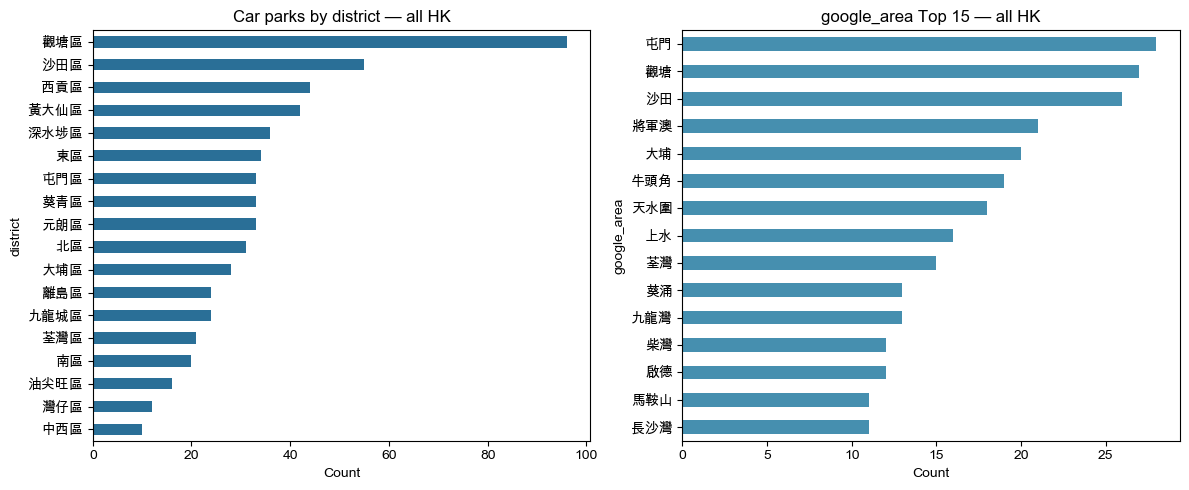

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

carparks["district"].value_counts().sort_values().plot(
    kind="barh", ax=axes[0], color="#2a6f97"
)
axes[0].set_title("Car parks by district — all HK")
axes[0].set_xlabel("Count")

(
    carparks["google_area"]
    .fillna("(missing)")
    .value_counts()
    .head(15)
    .sort_values()
    .plot(kind="barh", ax=axes[1], color="#468faf")
)
axes[1].set_title("google_area Top 15 — all HK")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

## A2 · 近期 vacancy_records（全港）

In [37]:
RECENT_DAYS = 14
since = datetime.now(HK_TZ) - timedelta(days=RECENT_DAYS)

vacancy = load_vacancy_frame(
    client, park_ids=carparks["park_id"].tolist(), since=since
)
vacancy = vacancy[vacancy["vacancy"] >= 0].copy()

print(f"近 {RECENT_DAYS} 日 · 全港")
print("筆數:", len(vacancy), "| 車場:", vacancy["park_id"].nunique())
if vacancy.empty:
    print("表係空 → 後面用 baseline + 即時 API")
else:
    print("範圍:", vacancy["collected_at"].min(), "→", vacancy["collected_at"].max())
    print(vacancy["district"].value_counts())

近 14 日 · 全港
筆數: 0 | 車場: 0
表係空 → 後面用 baseline + 即時 API


## A3 · 全港 baseline 摘要

In [38]:
baselines = load_baselines_dataframe(client=client)
if baselines.empty:
    raise RuntimeError("無 baseline：先跑 scripts/build_vacancy_baselines.py")

print("列數:", len(baselines), "| 車場:", baselines["park_id"].nunique())
print(baselines["n"].describe())

slot_dow = baselines[
    (baselines["half_hour"] >= 0)
    & (baselines["dow"].between(0, 6))
    & (baselines["is_weekend"] == -1)
].copy()

sample_park = slot_dow.groupby("park_id")["n"].sum().idxmax()
sample_row = carparks.loc[carparks["park_id"] == sample_park].iloc[0]
print("示範車場:", sample_park, sample_row["name"], f"({sample_row['district']})")

列數: 238611 | 車場: 511
count    238611.000000
mean        220.658612
std        1302.275812
min           1.000000
25%          62.000000
50%         104.000000
75%         144.000000
max       34911.000000
Name: n, dtype: float64
示範車場: tdc14p1030 小西灣三期停車場 (東區)


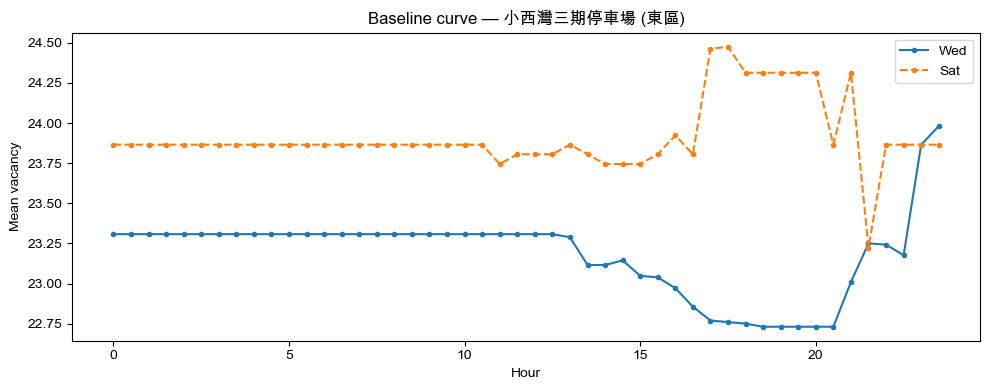

In [39]:
one = slot_dow[slot_dow["park_id"] == sample_park].copy()
one["hour"] = one["half_hour"] / 2.0

fig, ax = plt.subplots(figsize=(10, 4))
for dow, label, ls in [(2, "Wed", "-"), (5, "Sat", "--")]:
    sub = one[one["dow"] == dow].sort_values("half_hour")
    ax.plot(sub["hour"], sub["mean"], ls=ls, marker="o", ms=3, label=label)
ax.set_title(f"Baseline curve — {sample_row['name']} ({sample_row['district']})")
ax.set_xlabel("Hour")
ax.set_ylabel("Mean vacancy")
ax.legend()
plt.tight_layout()
plt.show()

## A4 · 全港 18 區 × 小時空置率熱力圖

Y 軸列出全部 district（約 18 行）。顏色係容量加權空置**率**（唔係原始空位格數），避免大停車場主導色階。

熱力圖區數: 18
區名: ['黃大仙區', '離島區', '觀塘區', '北區', '沙田區', '南區', '西貢區', '東區', '屯門區', '大埔區', '葵青區', '元朗區', '九龍城區', '中西區', '荃灣區', '油尖旺區', '灣仔區', '深水埗區']


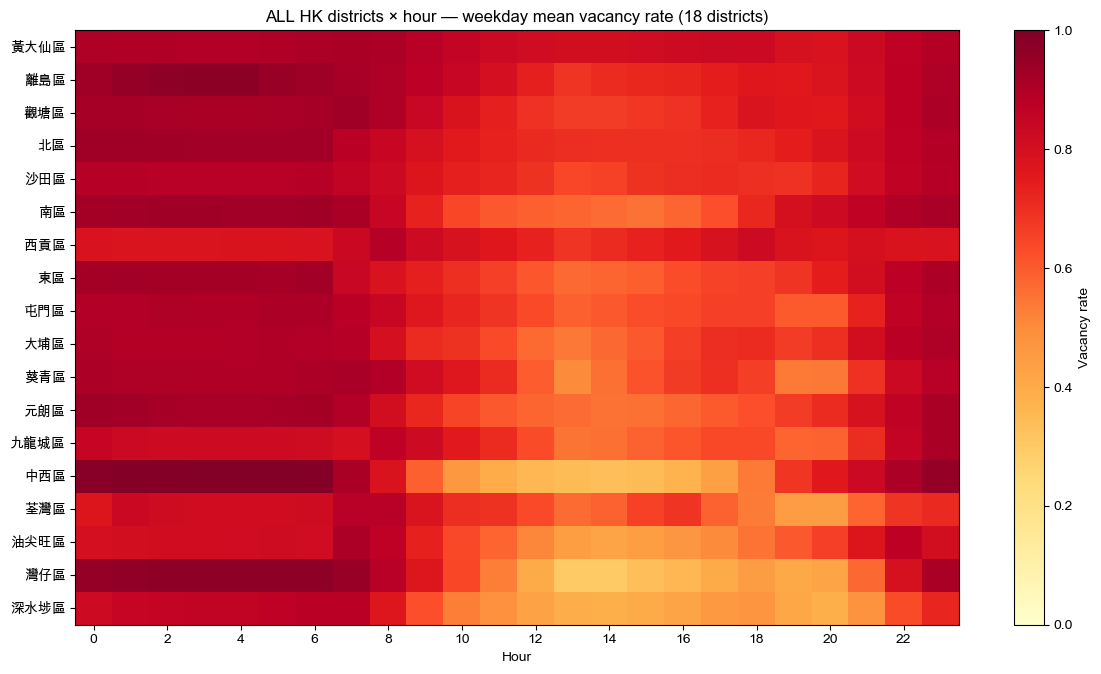

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
district,,,,,,,,,,,,,,,,,,,,,
黃大仙區,0.898736,0.896282,0.894913,0.891918,0.891754,0.894880,0.903968,0.910234,0.908188,0.881871,...,0.807435,0.812750,0.822540,0.830344,0.825292,0.789276,0.781625,0.824542,0.864267,0.889080
離島區,0.933209,0.954316,0.966380,0.970544,0.971732,0.947384,0.934281,0.920093,0.898960,0.874071,...,0.707860,0.717438,0.723650,0.739123,0.758084,0.754784,0.774129,0.823195,0.867363,0.899071
觀塘區,0.920670,0.919292,0.917362,0.913787,0.913413,0.916025,0.921596,0.930345,0.901648,0.836364,...,0.667935,0.677191,0.694503,0.727582,0.773898,0.758225,0.757064,0.812419,0.868498,0.907202
北區,0.931370,0.932086,0.929702,0.926669,0.928349,0.928339,0.926934,0.876209,0.841148,0.789171,...,0.697352,0.698762,0.698462,0.704950,0.715394,0.739196,0.773665,0.823302,0.864059,0.888361
沙田區,0.886392,0.884290,0.882669,0.881624,0.881497,0.882462,0.885187,0.858950,0.826056,0.769533,...,0.655016,0.689294,0.701576,0.709241,0.697423,0.692570,0.726211,0.813138,0.859765,0.883106
南區,0.925074,0.928618,0.930731,0.930336,0.927649,0.927254,0.930837,0.910314,0.842542,0.726734,...,0.564013,0.554673,0.580183,0.623586,0.718426,0.796061,0.820355,0.860171,0.896659,0.916001
西貢區,0.781420,0.776697,0.773850,0.773672,0.778401,0.778842,0.782479,0.835696,0.885873,0.822240,...,0.709218,0.728829,0.751437,0.787132,0.821491,0.780957,0.771119,0.795946,0.781203,0.783739
東區,0.925151,0.925835,0.924813,0.923283,0.922569,0.920881,0.926833,0.836154,0.783151,0.734669,...,0.580035,0.593604,0.627133,0.649746,0.658916,0.687372,0.738291,0.804823,0.873268,0.908667
屯門區,0.893080,0.893138,0.901483,0.898230,0.897510,0.903297,0.904797,0.878098,0.840222,0.764122,...,0.605271,0.625389,0.640471,0.658827,0.658517,0.599946,0.599437,0.727358,0.860911,0.893879


In [40]:
# 容量 proxy：觀察到嘅最大空位（否則用 baseline mean 最大值）。
# 官方 API `space` 覆蓋率好低（約 5%），唔可以單靠佢。
if not vacancy.empty:
    cap = vacancy.groupby("park_id")["vacancy"].max()
else:
    cap = pd.Series(dtype=float)
base_cap = baselines.groupby("park_id")["mean"].max()
capacity = (
    carparks[["park_id", "district"]]
    .assign(
        capacity=lambda d: d["park_id"].map(cap).fillna(d["park_id"].map(base_cap))
    )
    .dropna(subset=["district", "capacity"])
)
capacity = capacity[capacity["capacity"] > 0]

heat = (
    slot_dow.merge(capacity, on="park_id", how="inner")
    .assign(hour=lambda d: (d["half_hour"] // 2).astype(int))
)
heat_wd = heat[heat["dow"] < 5]  # 平日

# 區 × 小時：容量加權空置率
agg = heat_wd.groupby(["district", "hour"]).agg(
    vac=("mean", "sum"), cap=("capacity", "sum")
)
agg["rate"] = (agg["vac"] / agg["cap"]).clip(0, 1)
pivot = agg["rate"].unstack("hour")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

assert pivot.shape[0] >= 10, f"區數異常少：{pivot.shape[0]} — 檢查 baseline／carparks join"
print("熱力圖區數:", pivot.shape[0])
print("區名:", list(pivot.index))

fig, ax = plt.subplots(figsize=(12, max(5.0, 0.38 * len(pivot))))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("Hour")
ax.set_title(f"ALL HK districts × hour — weekday mean vacancy rate ({len(pivot)} districts)")
plt.colorbar(im, ax=ax, label="Vacancy rate")
plt.tight_layout()
plt.show()

pivot

## A5 · 即時 API vs baseline（每區 1 場）

即時車場數: 491 | 而家 half_hour=32 週六


,district,name,live,baseline
0,中西區,中山紀念公園,0,4.8
1,九龍城區,Airside,267,248.5
2,元朗區,屏欣停車場,7,11.9
3,北區,祥華A停車場,30,19.6
4,南區,數碼港停車場(一&二),396,366.9
5,大埔區,廣褔停車場,30,23.9
6,屯門區,屯門康景花園停車場,11,6.3
7,東區,愛東停車場,30,23.9
8,沙田區,科學園停車場 P1,242,261.1
9,油尖旺區,香港故宮文化博物館停車場,1,1.5


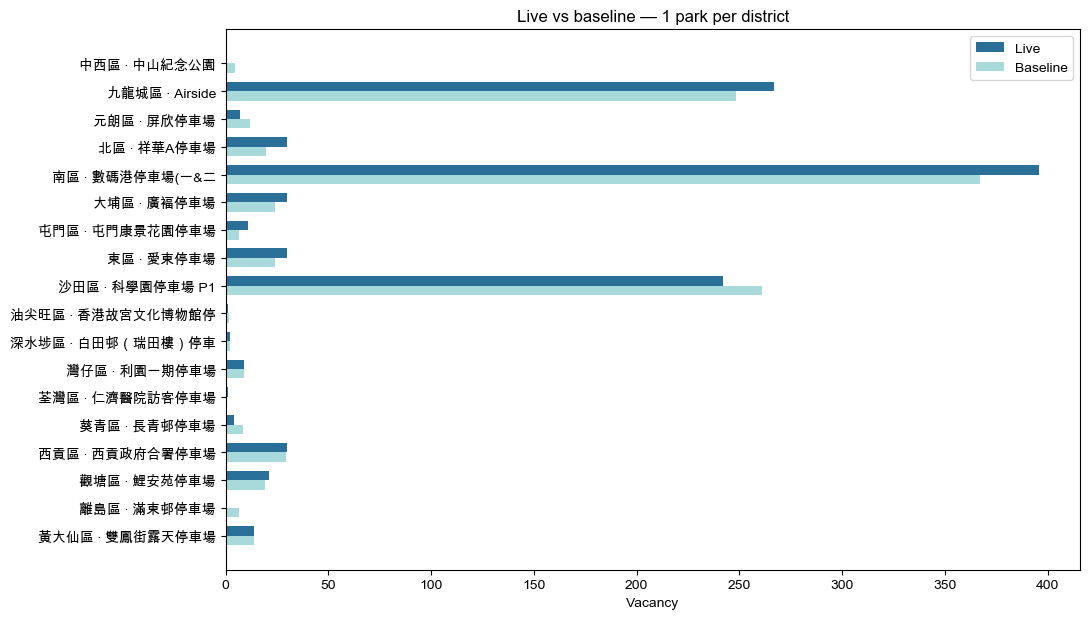

In [41]:
def fetch_live_private_car() -> dict[str, dict]:
    resp = requests.get(
        VACANCY_URL,
        params={"data": "vacancy", "lang": "zh_TW", "vehicleTypes": "privateCar"},
        timeout=30,
    )
    resp.raise_for_status()
    out: dict[str, dict] = {}
    for item in resp.json().get("results") or []:
        pid = str(item.get("park_Id") or "")
        private = item.get("privateCar") or []
        if not pid or not private:
            continue
        try:
            vac = int(private[0].get("vacancy"))
        except (TypeError, ValueError):
            continue
        if vac < 0:
            continue
        out[pid] = {"vacancy": vac, "lastupdate": private[0].get("lastupdate")}
    return out


def half_hour_now(ts: datetime | None = None) -> tuple[int, int]:
    ts = ts or datetime.now(HK_TZ)
    return ts.hour * 2 + (1 if ts.minute >= 30 else 0), ts.weekday()


live = fetch_live_private_car()
now_hh, now_dow = half_hour_now()
print("即時車場數:", len(live), f"| 而家 half_hour={now_hh} 週{WEEKDAY_CN[now_dow]}")

simple = (
    slot_dow[(slot_dow["half_hour"] == now_hh) & (slot_dow["dow"] == now_dow)]
    .set_index("park_id")["mean"]
)

rows = []
for district, grp in carparks.groupby("district", sort=True):
    for pid in grp["park_id"]:
        if pid in live and pid in simple.index:
            rows.append(
                {
                    "district": district,
                    "name": grp.loc[grp["park_id"] == pid, "name"].iloc[0],
                    "live": live[pid]["vacancy"],
                    "baseline": round(float(simple.loc[pid]), 1),
                }
            )
            break

compare_df = pd.DataFrame(rows)
display(compare_df)

if not compare_df.empty:
    fig, ax = plt.subplots(figsize=(11, max(4, 0.35 * len(compare_df))))
    y = np.arange(len(compare_df))
    labels = compare_df["district"] + " · " + compare_df["name"].str.slice(0, 10)
    ax.barh(y - 0.17, compare_df["live"], 0.34, label="Live", color="#2a6f97")
    ax.barh(y + 0.17, compare_df["baseline"], 0.34, label="Baseline", color="#a8dadc")
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel("Vacancy")
    ax.set_title("Live vs baseline — 1 park per district")
    ax.legend()
    plt.tight_layout()
    plt.show()

## B · 對齊 app 預測（shrinkage）

鏡像 `app.py` 嘅 `_shrink_mean`／`predict_park_vacancy_baseline`（唔 import app）。

In [42]:
def shrink_mean(
    primary: float | None,
    n_primary: int,
    prior: float | None,
    *,
    k: float = BASELINE_PRIOR_K,
) -> float | None:
    if primary is None and prior is None:
        return None
    if primary is None:
        return float(prior) if prior is not None else None
    if prior is None or n_primary <= 0:
        return float(primary)
    w = n_primary / (n_primary + k)
    return float(w * primary + (1.0 - w) * prior)


def predict_park_vacancy_baseline(
    park_id: str, half_hour: int, dow: int, packed: tuple
) -> tuple[float | None, dict]:
    (
        by_slot_dow,
        by_slot_weekend,
        by_slot,
        by_park,
        n_slot_dow,
        n_slot_weekend,
        n_slot,
        n_park,
    ) = packed

    is_weekend = 1 if dow >= 5 else 0
    mean_dow = by_slot_dow.get((park_id, half_hour, dow))
    n_dow = int(n_slot_dow.get((park_id, half_hour, dow), 0))
    mean_we = by_slot_weekend.get((park_id, half_hour, is_weekend))
    n_we = int(n_slot_weekend.get((park_id, half_hour, is_weekend), 0))
    mean_slot = by_slot.get((park_id, half_hour))
    n_s = int(n_slot.get((park_id, half_hour), 0))
    mean_park = by_park.get(park_id)
    n_p = int(n_park.get(park_id, 0))

    prior = mean_we if mean_we is not None else mean_slot
    if prior is None:
        prior = mean_park

    pred = shrink_mean(mean_dow, n_dow, prior)
    source, n_used = "同星期同時段", n_dow
    if pred is None:
        pred = shrink_mean(mean_we, n_we, mean_slot if mean_slot is not None else mean_park)
        source, n_used = "平日／週末同時段", n_we
    if pred is None:
        pred = mean_slot if mean_slot is not None else mean_park
        source = "同時段" if mean_slot is not None else "車場全日平均"
        n_used = n_s if mean_slot is not None else n_p
    if pred is None:
        return None, {"source": "無資料", "n": 0, "confidence": "低"}

    confidence = "高" if n_used >= 6 else ("中" if n_used >= 2 else "低")
    return float(pred), {"source": source, "n": int(n_used), "confidence": confidence}


packed = baselines_frame_to_maps(baselines)
pred, meta = predict_park_vacancy_baseline(sample_park, now_hh, now_dow, packed)
print(sample_row["name"], "→", None if pred is None else round(pred, 1), meta)

小西灣三期停車場 → 23.9 {'source': '同星期同時段', 'n': 105, 'confidence': '高'}


## B1 · 全港各區平均預測（週五 19:00）

全港 · 週五 19:00


,district,車場數,平均預測空位,中位預測空位
1,中西區,10,104.5,57.5
2,離島區,17,81.2,23.9
3,油尖旺區,14,78.0,25.7
4,南區,17,47.2,11.8
5,北區,26,41.6,12.4
6,九龍城區,17,39.1,19.0
7,荃灣區,18,38.2,9.7
8,沙田區,49,37.3,23.8
9,西貢區,40,35.0,23.9
10,灣仔區,12,29.1,19.8


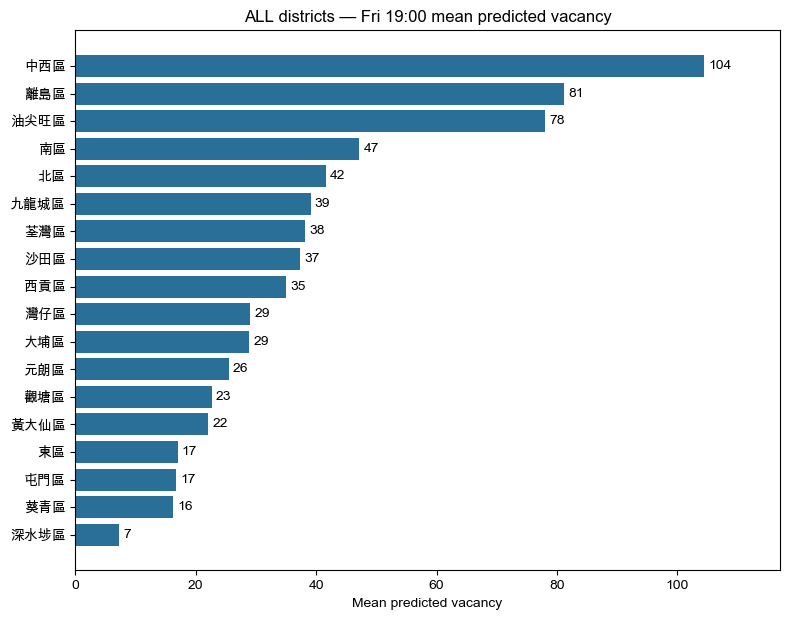

In [43]:
QUERY_HOUR, QUERY_DOW = 19, 4
QUERY_HALF = QUERY_HOUR * 2

district_rows = []
for district, grp in carparks.groupby("district", sort=True):
    preds = [
        p
        for pid in grp["park_id"]
        if (p := predict_park_vacancy_baseline(str(pid), QUERY_HALF, QUERY_DOW, packed)[0])
        is not None
    ]
    if preds:
        district_rows.append(
            {
                "district": district,
                "車場數": len(preds),
                "平均預測空位": round(float(np.mean(preds)), 1),
                "中位預測空位": round(float(np.median(preds)), 1),
            }
        )

district_rank = (
    pd.DataFrame(district_rows)
    .sort_values("平均預測空位", ascending=False)
    .reset_index(drop=True)
)
district_rank.index += 1
print(f"全港 · 週{WEEKDAY_CN[QUERY_DOW]} {QUERY_HOUR}:00")
display(district_rank)

fig, ax = plt.subplots(figsize=(8, max(4.5, 0.35 * len(district_rank))))
plot_df = district_rank.iloc[::-1]
bars = ax.barh(plot_df["district"], plot_df["平均預測空位"], color="#2a6f97")
ax.bar_label(bars, labels=[f"{v:.0f}" for v in plot_df["平均預測空位"]], padding=3)
ax.set_xlabel("Mean predicted vacancy")
ax.set_title(f"ALL districts — Fri {QUERY_HOUR}:00 mean predicted vacancy")
xmax = float(plot_df["平均預測空位"].max())
ax.set_xlim(0, xmax * 1.12)
plt.tight_layout()
plt.show()

## B2 · 附近推薦（全港車場池 · 中環示範）

In [44]:
def haversine_km(lat1, lon1, lat2, lon2) -> float:
    r = 6371.0
    p1, p2 = radians(lat1), radians(lat2)
    dp, dl = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dp / 2) ** 2 + cos(p1) * cos(p2) * sin(dl / 2) ** 2
    return float(2 * r * asin(sqrt(a)))


def parks_near(lat, lon, parks, radius_km=NEARBY_RADIUS_KM, fallback_km=NEARBY_RADIUS_FALLBACK_KM):
    work = parks.dropna(subset=["latitude", "longitude"]).copy()
    work["距離(公里)"] = [
        haversine_km(lat, lon, float(a), float(b))
        for a, b in zip(work["latitude"], work["longitude"])
    ]
    for radius in (radius_km, fallback_km):
        hit = work[work["距離(公里)"] <= radius].sort_values("距離(公里)")
        if not hit.empty:
            return hit.reset_index(drop=True), float(radius)
    return work.iloc[0:0].copy(), None


DEMO_LAT, DEMO_LON = 22.2819, 114.1588  # 中環
nearby, used_r = parks_near(DEMO_LAT, DEMO_LON, carparks)
print(f"({DEMO_LAT}, {DEMO_LON}) · 半徑 {used_r} km · {len(nearby)} 場")
print("涉及地區:", sorted(nearby["district"].dropna().unique()))

near_rows = []
for _, row in nearby.iterrows():
    pid = str(row["park_id"])
    pred, meta = predict_park_vacancy_baseline(pid, QUERY_HALF, QUERY_DOW, packed)
    if pred is None:
        continue
    dist = float(row["距離(公里)"])
    near_rows.append(
        {
            "name": row["name"],
            "district": row["district"],
            "距離(公里)": round(dist, 3),
            "預測空位": round(pred, 1),
            "score": round(pred / ((1.0 + dist) ** NEARBY_DISTANCE_SCORE_POWER), 2),
            "live": live.get(pid, {}).get("vacancy"),
            "confidence": meta["confidence"],
        }
    )

nearby_rank = (
    pd.DataFrame(near_rows)
    .sort_values("score", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
nearby_rank.index += 1
display(nearby_rank)

(22.2819, 114.1588) · 半徑 1.2 km · 5 場
涉及地區: ['中西區']


,name,district,距離(公里),預測空位,score,live,confidence
1,天星停車場,中西區,0.194,147.1,103.24,109,高
2,林士街停車場,中西區,0.839,299.7,88.63,92,高
3,港鐵香港站停車場,中西區,0.467,138.7,64.48,120,高
4,大會堂停車場,中西區,0.344,71.0,39.33,10,高
5,金鐘道政府合署,中西區,0.700,44.0,15.22,90,高


## 小結

- 全 notebook 以 **全港 `district`** 為核心
- A4 熱力圖用容量加權空置**率**（標題含 `ALL HK districts` 同區數 ≈ 18）
- B1 各區平均預測；B2 全港車場池做附近推薦
- 語音／LLM／收費邏輯只喺 `app.py`